# Project: classify imagined left-hand vs. right-hand movement from EEG

**Goal:** given a few seconds of EEG while someone *imagines* moving their left or right hand, predict which hand they imagined. 

**Data:** PhysioNet EEG Motor Movement/Imagery dataset, fetched via `mne.datasets.eegbci`. Runs 4, 8, 12 = motor imagery, left vs. right hand.

**Official reference** in the MNE docs/examples *"Motor imagery decoding from EEG data using the Common Spatial Pattern algorithm"* (`decoding_csp_eeg.py` in `mne.tools`'s examples gallery). 

## 1. Downloading data

In [19]:
import mne
from mne.datasets import eegbci
import matplotlib.pyplot as plt
import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline


subject = 1
runs = [4, 8, 12]  # motor imagery, left vs right hand

raw_fnames = eegbci.load_data(subject, runs)
raws = [mne.io.read_raw_edf(f, preload=True) for f in raw_fnames]
raw = mne.concatenate_raws(raws)
print(raw.info)

Extracting EDF parameters from /Users/marinad/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from /Users/marinad/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R08.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from /Users/marinad/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R12.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id:

In [10]:
raw

<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

## 2. Clean up channel names and set electrode positions
The EDF files use nonstandard channel names (e.g. `Fcz.` with a trailing dot). `eegbci.standardize` fixes them to match a standard naming scheme so.

In [3]:
eegbci.standardize(raw) #standardizes names eg Fc5 to FC5
montage = mne.channels.make_standard_montage("standard_1005") #template that has all the possible electrode coordinates for a given EEG cap I think? this one has like 343 possible locations
raw.set_montage(montage) #the actual data has like 64 electrodes, so this will just use the coordinates for those 64 electrodes from the template

/var/folders/b4/lldwp1t53hnd9vz2x7j81vhc0000gn/T/ipykernel_15065/1299696260.py:2: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

## 3. Filter 
Motor imagery shows up as a *decrease* in 8-30 Hz power over sensorimotor cortex (event-related desynchronization) so I need to filter to isolate that band. (ie usually this brain area's 'idling' frequency is 8-30hz, but this type of activity drops when simulating/doing a movement.)

In [4]:
raw.filter(8.0, 30.0, fir_design="firwin", skip_by_annotation="edge") #the frequency refers to the synchronized activity of a large population of neurons, not single neuron firing frequency.

Filtering raw data in 3 contiguous segments
Setting up band-pass filter from 8 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 265 samples (1.656 s)



<RawEDF | S001R04.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

## 4. Extract events and epoch
I'll first view the annotations -> data abt events in the experiment. I'll turn it into df to get a nice view as a table.
This dataset marks events via annotations: `T1` = left hand, `T2` = right hand (`T0` = rest, but I'm dropping that).

In [17]:
%pip install pandas

import pandas as pd

print(raw.annotations)
display(raw.annotations.to_data_frame())

print(raw.annotations) 
raw.annotations.to_data_frame() 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
<Annotations | 94 segments: BAD boundary (2), EDGE boundary (2), T0 (45), ...>


,onset,duration,description
0,2009-08-12 16:15:00.000,4.2,T0
1,2009-08-12 16:15:04.200,4.1,T2
2,2009-08-12 16:15:08.300,4.2,T0
3,2009-08-12 16:15:12.500,4.1,T1
4,2009-08-12 16:15:16.600,4.2,T0
...,...,...,...
89,2009-08-12 16:20:53.800,4.1,T2
90,2009-08-12 16:20:57.900,4.2,T0
91,2009-08-12 16:21:02.100,4.1,T1
92,2009-08-12 16:21:06.200,4.2,T0


<Annotations | 94 segments: BAD boundary (2), EDGE boundary (2), T0 (45), ...>


,onset,duration,description
0,2009-08-12 16:15:00.000,4.2,T0
1,2009-08-12 16:15:04.200,4.1,T2
2,2009-08-12 16:15:08.300,4.2,T0
3,2009-08-12 16:15:12.500,4.1,T1
4,2009-08-12 16:15:16.600,4.2,T0
...,...,...,...
89,2009-08-12 16:20:53.800,4.1,T2
90,2009-08-12 16:20:57.900,4.2,T0
91,2009-08-12 16:21:02.100,4.1,T1
92,2009-08-12 16:21:06.200,4.2,T0


ok so I've got events happening that last 4.1 seconds, with 4.2-second long breaks in between (T0 is the break). I can define my epoch length based on this. I'll also create a dict where T1's value is 1 and T2 is 2. I'll choose only those events which are eeg, and all these parameters will be used to define my epochs. 

In [18]:
events, _ = mne.events_from_annotations(raw, event_id=dict(T1=1, T2=2))
picks = mne.pick_types(raw.info, eeg=True, exclude="bads")

tmin, tmax = -1.0, 4.0  # seconds relative to cue onset — feel free to experiment with this window
epochs = mne.Epochs(
    raw, events, event_id=dict(left=1, right=2),
    tmin=tmin, tmax=tmax, picks=picks, baseline=None, preload=True,
)
labels = epochs.events[:, -1] - 1  # 0 = left, 1 = right. the epochs.events array has three column and it is the last one that has 1 for left and 2 for right. 0 & 1 is the convention for scikit-learn classifying stuff, which is why I subtract 1.
print(epochs)

Used Annotations descriptions: ['T1', 'T2']
Not setting metadata
45 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 45 events and 801 original time points ...
0 bad epochs dropped
<Epochs | 45 events (all good), -1 – 4 s (baseline off), ~17.7 MiB, data loaded,
 'left': 23
 'right': 22>


## 5. build a CSP + classifier pipeline

**Claude's notes for me:**
*Common Spatial Patterns (`mne.decoding.CSP`) finds spatial filters (weighted combinations of channels) that maximize the power *difference* between the two classes — i.e. it learns which combination of electrodes best separates "left-hand imagery" from "right-hand imagery" band power.*

*Things to figure out / try:*
*- Import `CSP` from `mne.decoding` and a classifier from `sklearn` (logistic regression or LDA are standard choices here).*
*- Chain them with `sklearn.pipeline.Pipeline`.*
*- CSP expects the raw epoch data array: `epochs.get_data()`, shape `(n_epochs, n_channels, n_times)`.*

**me:** I'll also do cross-validation. I'll try leave-one-out because apparently that's good for small datasets


In [20]:
#cross-validation
from sklearn.model_selection import LeaveOneOut, cross_val_score
cv = LeaveOneOut() #importing the cv method I wanna use

#creating a pipeline with CPA and then LDA as the classifier
lda = LinearDiscriminantAnalysis() #creating the classifier
csp = mne.decoding.CSP(n_components=4, reg=None, log=True, norm_trace=False) #creating the csp object
clf = Pipeline([('CSP', csp), ('LDA', lda)]) #creating the pipeline 
scores = cross_val_score(clf, epochs.get_data(), labels, cv=cv, n_jobs=1) #running the cross validation
print("Classification accuracy: %f ± %f" % (np.mean(scores), np.std(scores))) #printing the results


Computing rank from data with rank=None
    Using tolerance 0.00033 (2.2e-16 eps * 64 dim * 2.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.00033 (2.2e-16 eps * 64 dim * 2.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.00033 (2.2e-16 eps * 64 dim * 2.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMP

wait why is the standard deviation SO high lmao (accuracy = 77.8%, sd = 41.6%)

oh so according to Claude it's supposed to be high with leave-one-out cause it's like 45 values of 1 or 0. so I'll try another cross-validation method to get results I'm more used to lol.

## Trying other cv methods? 

I'll try monte-carlo cause it sounds really cool

In [21]:
# Monte Carlo / ShuffleSplit — any n_splits regardless of N, overlap allowed
from sklearn.model_selection import ShuffleSplit, cross_val_score
cv1 = ShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

#using the previous pipeline but the new cross-validation method
scores1 = cross_val_score(clf, epochs.get_data(), labels, cv=cv1, n_jobs=1) #running the cross validation
print("Classification accuracy: %f ± %f" % (np.mean(scores1), np.std(scores1))) #printing the results

Computing rank from data with rank=None
    Using tolerance 0.0003 (2.2e-16 eps * 64 dim * 2.1e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.0003 (2.2e-16 eps * 64 dim * 2.1e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 0.0003 (2.2e-16 eps * 64 dim * 2.1e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRI

ok so we have a smaller standard deviatio (12.4%) but also worse accuracy (62.2%), which is pretty close to the chance lvl of 50% :(

## 7. (Bonus) Visualize the CSP spatial patterns
Fit CSP alone (outside the pipeline) on the full dataset and call `csp.plot_patterns(epochs.info)` — you should see the pattern concentrate over motor cortex, roughly symmetric for left vs. right.

Computing rank from data with rank=None
    Using tolerance 0.00033 (2.2e-16 eps * 64 dim * 2.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
NOTE: plot_patterns() is a legacy function. New code should use get_spatial_filter_from_estimator(clf, info=info).plot_patterns().


/var/folders/b4/lldwp1t53hnd9vz2x7j81vhc0000gn/T/ipykernel_15065/2553582293.py:2: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  csp.plot_patterns(epochs.info)


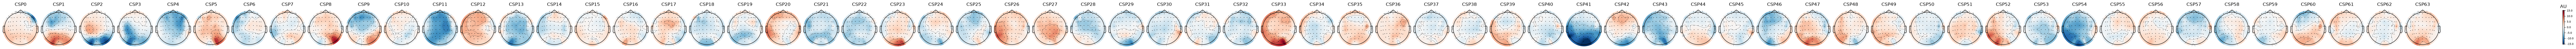

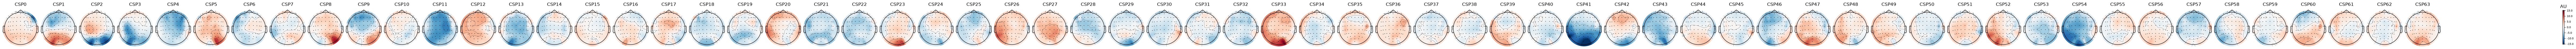

In [24]:


csp.fit(epochs.get_data(), labels) 
csp.plot_patterns(epochs.info)
